# 8-1. Stable Diffusion · Inpainting 실습 + 내 실험

- 위쪽: 강사 노트북 셀 그대로 (출력 포함). "내 메모" 셀만 내가 끼워 넣음
- 그 아래: 내가 추가한 실험 A1 · A2 · B1 · B2
- 실험마다 조건 · 내 예측 · 결과 · 해석은 [`analysis.md`](analysis.md)에 정리했다.
- 맨 끝에 회고(KPT)가 있다. 8-2(AnomalyAny) 노트북과 함께 본 프로젝트 전체 결과:

| 실험 | 결과 |
| --- | --- |
| A1 guidance 1 / 7.5 / 20 | 시간은 같고, 20은 과장됨 → 결함 생성엔 과장된 균열로 미탐 위험 |
| A2 fp32 → fp16 | 메모리 6.33 → 3.42GB, 시간 19.44 → 5.01초, 그림 거의 같음 |
| A3 steps 10 / 20 / 30 / 50 | 시간은 단계 수에 비례, 30에서 세부가 채워지고 50은 더 좋아지지 않음 |
| B1 · B2 실제 PCB Inpainting | 마스크 바깥 글자까지 뭉개짐 → 원본 되붙이면 글자는 돌아오고 이음새가 남음 |
| AnomalyAny 강사 출력 4장 | crack을 민 자리는 바뀌지만 균열 모양은 1장(커넥터)뿐 |
| C1 AnomalyAny on T4 | OOM. 해상도 · fp16 · autocast 모두 실패, 생성 중 역전파 때문으로 보임 |

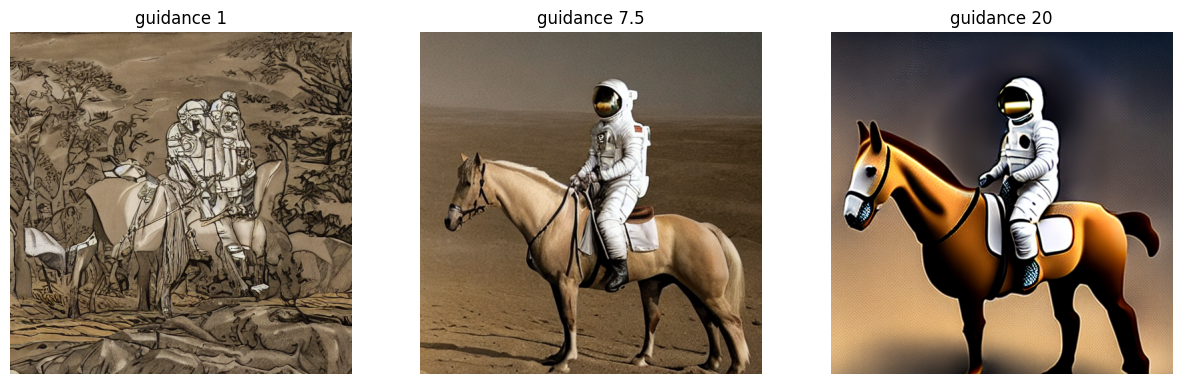

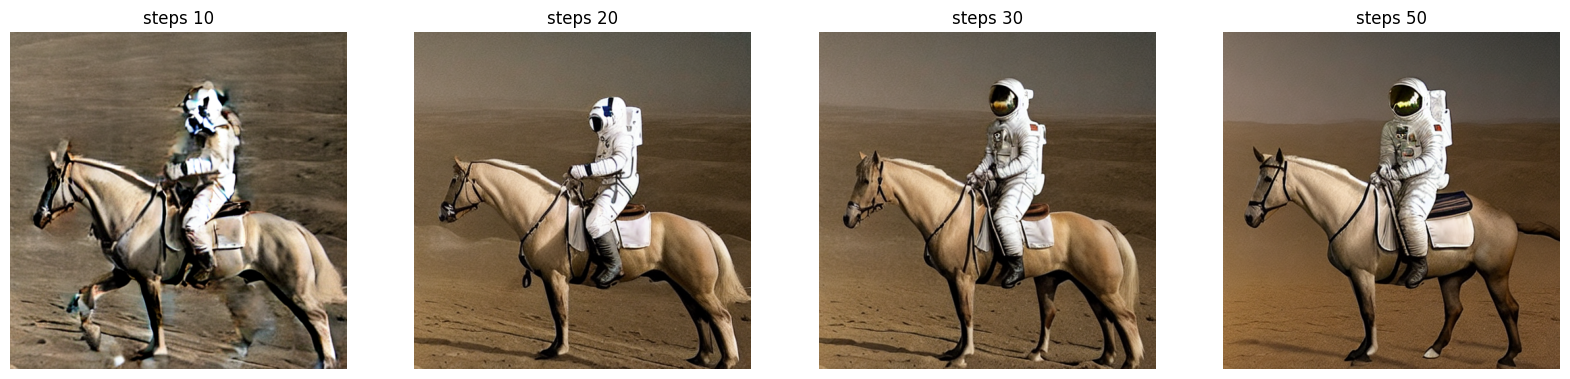

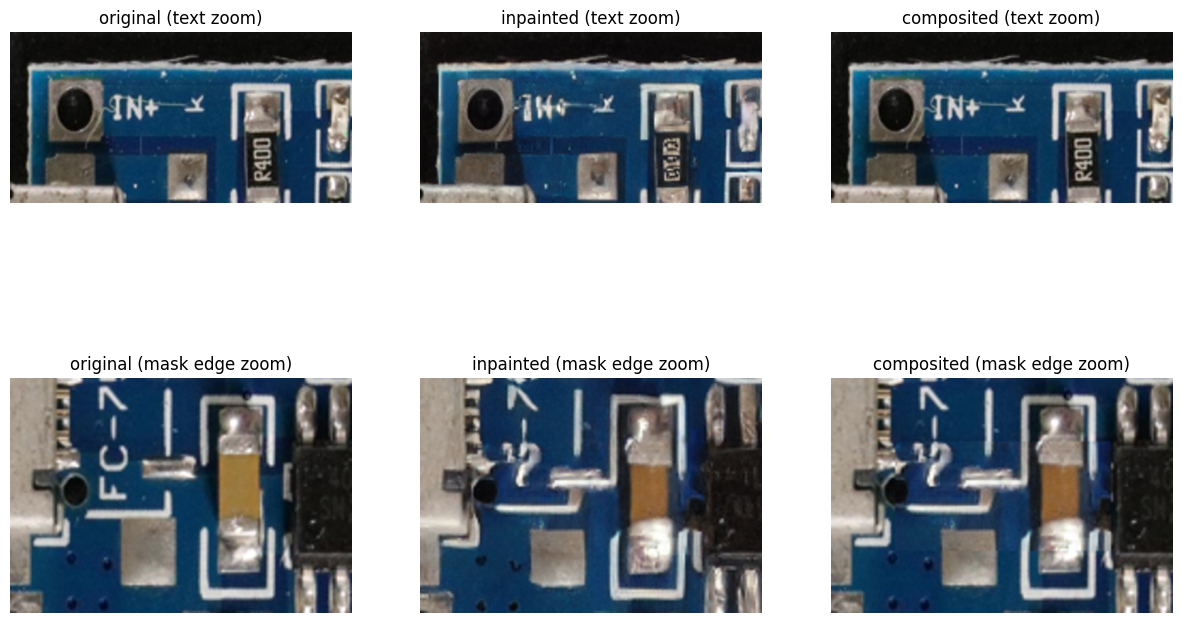


In [ ]:
# !pip install diffusers transformers accelerate torch torchvision

In [ ]:
import diffusers
import transformers

diffusers.__version__

'0.33.1'

In [ ]:
transformers.__version__

'4.52.4'

In [ ]:
# !pip install diffusers==0.33.1
# !pip install transformers==4.52.4

In [ ]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [ ]:
from diffusers import StableDiffusionPipeline, StableDiffusionInpaintPipeline
from PIL import Image
import matplotlib.pyplot as plt

def display_image(image):
    plt.imshow(image)
    plt.axis('off')
    plt.show()

**내 메모 (아래 강사 셀)**
- `device` 는 CPU 대비가 있는데 `torch_dtype=torch.float16`, `autocast("cuda")` 는 고정이라 CPU에서는 fp16 연산이 실패한다. 강사도 셀 8에서 `float16 if device == "cuda" else float32` 로 고쳤다.
- `generator` 를 만들고 `# generator=generator` 로 주석 처리해서 시드가 적용되지 않는다. 다시 돌리면 다른 그림이 나온다.
- negative prompt의 `"normal, no defect"` 는 결함 생성용 흔적이다. 말 탄 우주인 그림에는 결함이 생길 대상이 없어서 의미가 없다.

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Text-to-Image pipeline loaded.
Generating image for prompt: 'A photo of man riding a horse in the moon wearing astronaut outfits'


  0%|          | 0/30 [00:00<?, ?it/s]

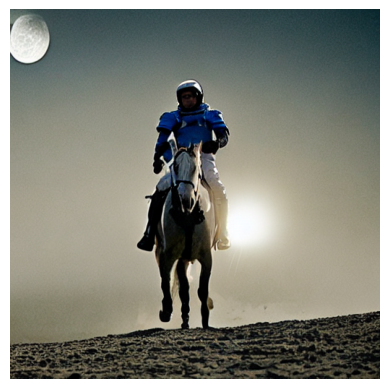

Image saved as generated_defect_0.png


In [ ]:
# --- 1.1 파이프라인 로드 ---
model_id_text2img = "runwayml/stable-diffusion-v1-5"
pipe_text2img = StableDiffusionPipeline.from_pretrained(model_id_text2img, torch_dtype=torch.float16)
pipe_text2img = pipe_text2img.to(device)
print("Text-to-Image pipeline loaded.")

# --- 1.2 프롬프트 정의 및 이미지 생성 ---
prompt_defect = "A photo of man riding a horse in the moon wearing astronaut outfits"
negative_prompt = "blurry, deformed, cartoon, painting, illustration, normal, no defect"

# 파라미터 설정
num_steps = 30
guidance_scale_val = 8.5
num_images_per_prompt = 1 # 한 번에 여러 개 생성 가능

print(f"Generating image for prompt: '{prompt_defect}'")
# seed 고정으로 재현성 확보 (선택 사항)
generator = torch.Generator(device=device).manual_seed(42)

with torch.autocast("cuda"): # float16 연산 시
    generated_images = pipe_text2img(
        prompt_defect,
        negative_prompt=negative_prompt,
        num_inference_steps=num_steps,
        guidance_scale=guidance_scale_val,
        num_images_per_prompt=num_images_per_prompt,
        # generator=generator
    ).images

# --- 1.3 결과 확인 및 저장 ---
for i, image in enumerate(generated_images):
    display_image(image)
    try:
        image.save(f"generated_defect_{i}.png")
        print(f"Image saved as generated_defect_{i}.png")
    except Exception as e:
        print(f"Error saving image: {e}")


**내 메모 (아래 강사 셀, 회색판)**
- **내 예측** (10-10 다시 볼 때): 배경이 밝은 회색 단색이라 찌그러짐을 표현하기 어려워서, 실제 금속판처럼 그럴듯하게 나오지는 않을 것 같다.
- **결과**: 맞음. 스티커처럼 붙은 검은 얼룩이고 움푹 들어간 느낌이 없다.
- **해석**: 회색판에는 빛(그림자)과 재질(금속 반사) 정보가 없다. 처음엔 그림자(빛)까지만 떠올렸고 재질은 못 떠올렸다. Inpainting은 마스크 바깥의 빛·재질을 단서로 안을 채운다.

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Inpainting pipeline loaded.
Using placeholder initial image and mask.


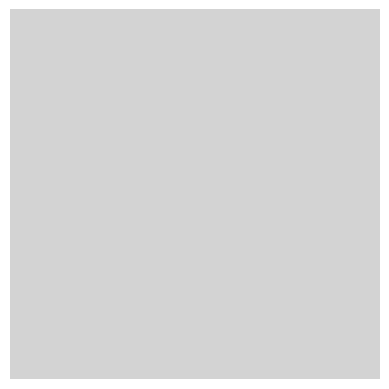

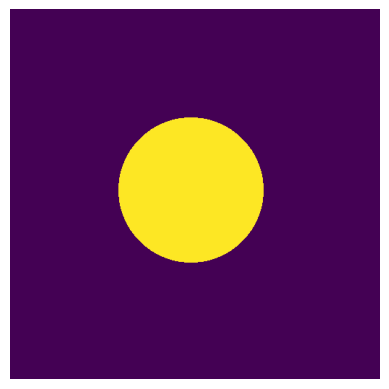

Inpainting with prompt: 'A deep circular dent with rough edges'


  0%|          | 0/50 [00:00<?, ?it/s]

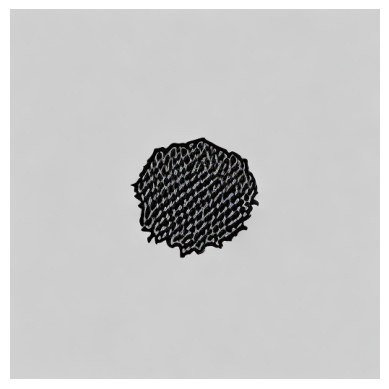

Image saved as inpainted_defect_0.png


In [ ]:
# --- 2.1 파이프라인 로드 ---
# Inpainting 전용 모델 사용
model_id_inpaint = "stabilityai/stable-diffusion-2-inpainting" # 또는 다른 inpainting 모델
try:
    pipe_inpaint = StableDiffusionInpaintPipeline.from_pretrained(model_id_inpaint, torch_dtype=torch.float16)
    pipe_inpaint = pipe_inpaint.to(device)
    print("Inpainting pipeline loaded.")
except Exception as e:
    print(f"Could not load inpainting pipeline: {e}. Skipping inpainting part or use a general pipeline.")
    pipe_inpaint = None # 예외 처리

if pipe_inpaint:
    # --- 2.2 원본 이미지 및 마스크 준비 ---
    init_image = Image.new("RGB", (512, 512), "lightgray") # 밝은 회색 배경
    mask_image = Image.new("L", (512, 512), "black")
    from PIL import ImageDraw
    draw = ImageDraw.Draw(mask_image)
    draw.ellipse(((150, 150), (350, 350)), fill="white") # 중앙 흰색 원형 마스크
    print("Using placeholder initial image and mask.")
    display_image(init_image)
    display_image(mask_image)


    # --- 2.3 프롬프트 정의 및 이미지 생성 ---
    prompt_inpaint_defect = "A deep circular dent with rough edges"
    negative_prompt_inpaint = "smooth, perfect, flat, no dent, blurry"

    print(f"Inpainting with prompt: '{prompt_inpaint_defect}'")
    with torch.autocast("cuda"):
        inpainted_images = pipe_inpaint(
            prompt=prompt_inpaint_defect,
            image=init_image,
            mask_image=mask_image,
            negative_prompt=negative_prompt_inpaint,
            num_inference_steps=50, # Inpainting은 조금 더 많은 step이 필요할 수 있음
            guidance_scale=7.5
        ).images

    # --- 2.4 결과 확인 및 저장 ---
    for i, image in enumerate(inpainted_images):
        display_image(image)
        try:
            image.save(f"inpainted_defect_{i}.png")
            print(f"Image saved as inpainted_defect_{i}.png")
        except Exception as e:
            print(f"Error saving image: {e}")

# TODO: 다양한 원본 이미지, 마스크, 프롬프트로 실험해보세요!
#       예: 실제 정상 제품 이미지에 사용자가 직접 그린 마스크 적용

**내 메모 (아래 강사 셀, 해변)**
- 실제 사진이면 보물 상자에 그림자가 생기고 파도가 상자를 감싼다. 상자 색이 바다를 따라간 것도 주변을 단서로 쓴다는 증거다.
- `stabilityai/stable-diffusion-2-inpainting` 은 지금 Hub에서 401이 나서, 실험 B1에서는 SD1.5 inpainting으로 바꿨다.

Using device: cuda


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Inpainting pipeline loaded with stabilityai/stable-diffusion-2-inpainting.
Image loaded and resized to 512x512.


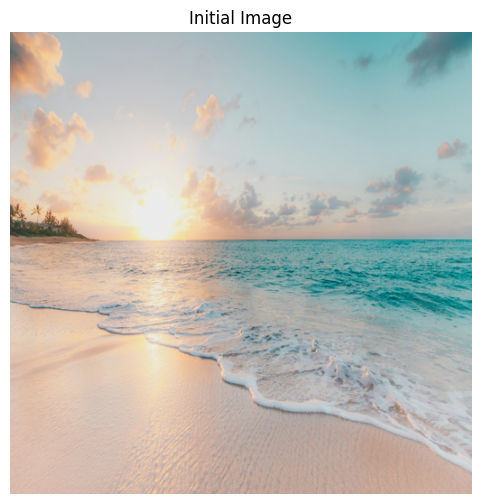

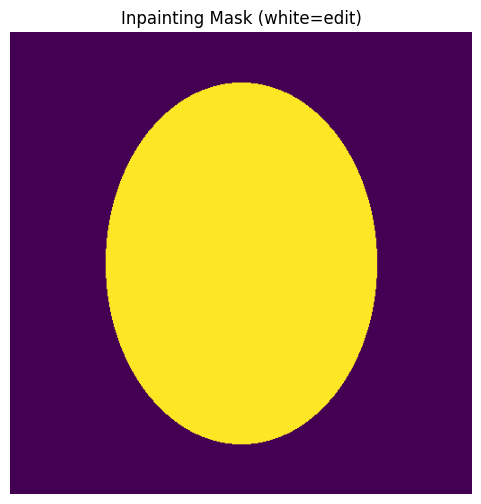

Running inpainting with prompt: A treasure chest buried in the sand


  0%|          | 0/50 [00:00<?, ?it/s]

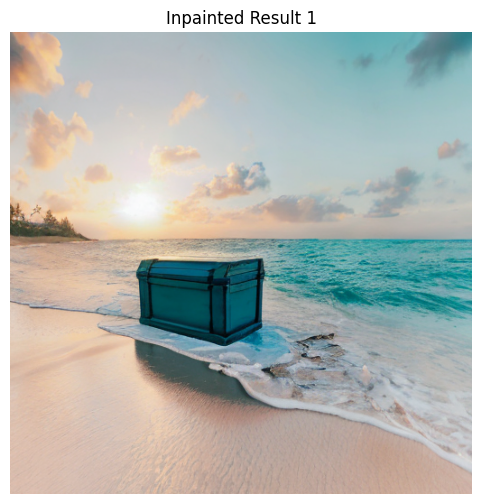

Saved: result_inpainted_0.png


In [ ]:
import torch
from diffusers import StableDiffusionInpaintPipeline
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import requests
from io import BytesIO

# --- 1. 디바이스 설정 ---
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# --- 2. 이미지 시각화 함수 ---
def display_image(image, title="Generated Image"):
    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.title(title)
    plt.axis('off')
    plt.show()

# --- 3. 파이프라인 로딩 ---
model_id_inpaint = "stabilityai/stable-diffusion-2-inpainting"
try:
    pipe_inpaint = StableDiffusionInpaintPipeline.from_pretrained(
        model_id_inpaint,
        torch_dtype=torch.float16 if device == "cuda" else torch.float32
    )
    pipe_inpaint = pipe_inpaint.to(device)
    print(f"Inpainting pipeline loaded with {model_id_inpaint}.")
except Exception as e:
    print(f"Could not load inpainting pipeline: {e}")
    pipe_inpaint = None

# --- 4. 이미지와 마스크 준비 ---
if pipe_inpaint:
    # 이미지 로드
    image_url = "https://images.unsplash.com/photo-1507525428034-b723cf961d3e?q=80&w=2070&auto=format&fit=crop"
    try:
        response = requests.get(image_url)
        response.raise_for_status()
        init_image = Image.open(BytesIO(response.content)).convert("RGB").resize((512, 512))
        print("Image loaded and resized to 512x512.")
    except Exception as e:
        print(f"Image load failed: {e}. Using placeholder image.")
        init_image = Image.new("RGB", (512, 512))
        draw = ImageDraw.Draw(init_image)
        draw.rectangle([0, 0, 512, 280], fill="skyblue")
        draw.rectangle([0, 280, 512, 512], fill="goldenrod")
        draw.ellipse([400, 60, 440, 100], fill="gold")

    # 마스크 생성 (중앙 타원형)
    mask_image = Image.new("L", (512, 512), 0)  # 검정 배경
    draw = ImageDraw.Draw(mask_image)
    ellipse_box = [106, 56, 406, 456]  # 대략 중앙 타원 (너비 300, 높이 400)
    draw.ellipse(ellipse_box, fill=255)  # 흰색 영역을 인페인팅할 영역으로

    # 이미지 확인
    display_image(init_image, "Initial Image")
    display_image(mask_image, "Inpainting Mask (white=edit)")

    # --- 5. 프롬프트 정의 ---
    prompt = "A treasure chest buried in the sand"
    negative_prompt = "blurry, deformed, cartoon, illustration, watermark, text, signature, extra limbs"

    print(f"Running inpainting with prompt: {prompt}")

    generator = torch.Generator(device=device).manual_seed(1234)

    # --- 6. 인페인팅 수행 ---
    if device == "cuda":
        with torch.autocast("cuda"):
            result = pipe_inpaint(
                prompt=prompt,
                image=init_image,
                mask_image=mask_image,
                negative_prompt=negative_prompt,
                guidance_scale=8.5,
                num_inference_steps=50,
                generator=generator
            )
    else:
        result = pipe_inpaint(
            prompt=prompt,
            image=init_image,
            mask_image=mask_image,
            negative_prompt=negative_prompt,
            guidance_scale=8.5,
            num_inference_steps=50,
            generator=generator
        )

    # --- 7. 결과 출력 및 저장 ---
    if result and result.images:
        for i, out_img in enumerate(result.images):
            display_image(out_img, f"Inpainted Result {i+1}")
            out_img.save(f"result_inpainted_{i}.png")
            print(f"Saved: result_inpainted_{i}.png")
    else:
        print("No images returned from inpainting.")

else:
    print("Pipeline not loaded. Cannot run inpainting.")


In [1]:
# [준비] 라이브러리 설치
!pip install -q diffusers transformers accelerate

## 실험 A1. guidance_scale 1 / 7.5 / 20
- 조건: 같은 프롬프트, 시드 42, steps 30, fp16
- **내 예측**: 20이 가장 느릴 것 같다. 1은 프롬프트의 일부만 남을 것 같은데, 모델이 프롬프트의 어디에 attention할지 몰라서 확신은 없다.
- **결과**: 시간은 셋 다 4.5초로 같음 → 틀림. 그림은 1이 연필 스케치, 20이 만화처럼 과함.
- **해석**: guidance는 프롬프트 있을 때/없을 때 예측 차이에 곱하는 배수라 계산량이 같다. 20이면 너무 밀어서 과장된다. 결함 생성에 이렇게 쓰면 균열이 과장되고 색과 대비가 세질 텐데, 실제 공장 균열은 대부분 가늘고 희미하니 그걸로 학습한 모델은 미탐을 낼 것 같다.
- 참고: 시간 측정 전에 2단계로 한 번 돌리는 준비 호출에서 안전 필터가 검은 그림을 낸 경고가 있었는데(출력 정리하며 지움), 비교한 세 장은 모두 정상이다.

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

...

guidance=   1  time=4.53s


  0%|          | 0/30 [00:00<?, ?it/s]

guidance= 7.5  time=4.49s


  0%|          | 0/30 [00:00<?, ?it/s]

guidance=  20  time=4.53s


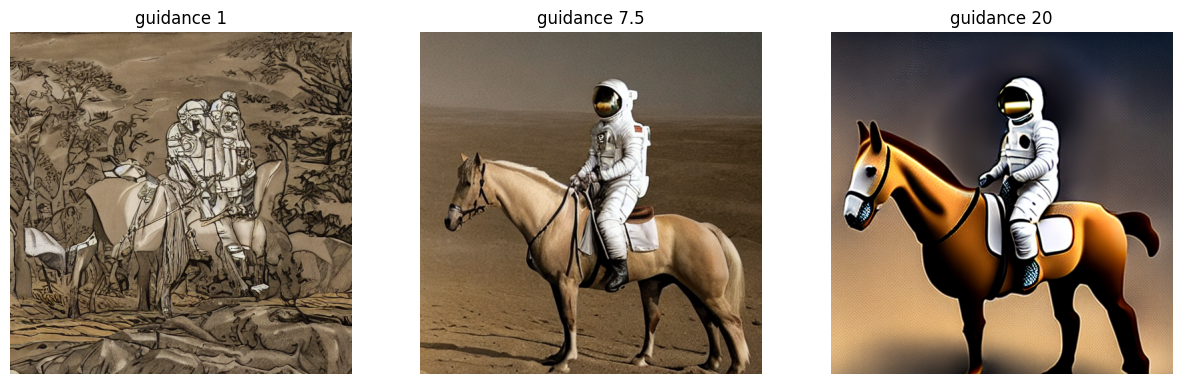

In [ ]:
# [실험 A1] guidance_scale 1 / 7.5 / 20 (같은 시드 42, 같은 프롬프트, steps 30)
import time
import torch
import matplotlib.pyplot as plt
from diffusers import StableDiffusionPipeline
try:
    pipe = StableDiffusionPipeline.from_pretrained('runwayml/stable-diffusion-v1-5', torch_dtype=torch.float16).to('cuda')
except Exception as e:
    print('runwayml 실패 → 미러 사용:', type(e).__name__)
    pipe = StableDiffusionPipeline.from_pretrained('stable-diffusion-v1-5/stable-diffusion-v1-5', torch_dtype=torch.float16).to('cuda')
prompt = 'A photo of man riding a horse in the moon wearing astronaut outfits'
pipe(prompt, num_inference_steps=2)
imgs = []
for g in [1, 7.5, 20]:
    gen = torch.Generator('cuda').manual_seed(42)
    torch.cuda.synchronize()
    t = time.time()
    img = pipe(prompt, num_inference_steps=30, guidance_scale=g, generator=gen).images[0]
    torch.cuda.synchronize()
    print(f'guidance={g:>4}  time={time.time() - t:.2f}s')
    imgs.append(img)
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, im, g in zip(ax, imgs, [1, 7.5, 20]):
    a.imshow(im)
    a.set_title(f'guidance {g}')
    a.axis('off')
plt.show()

## 실험 A2. fp32 vs fp16
- 조건: 시드 42, guidance 7.5, steps 30. 시간과 최대 GPU 메모리를 잰다.
- **내 예측**: 메모리는 절반쯤으로 줄고 생성 시간도 짧아질 것 같다. 숫자 표현을 낮췄으니 그림 품질은 조금 뭉개질 것 같다.
- **결과**: 6.33 → 3.42GB, 19.44 → 5.01초. 그림은 거의 같음 → 품질은 틀림.
- **해석**: 그림은 마지막에 0~255 정수로 반올림된다. 127.53과 127.5가 둘 다 128이 되니 소수점 아래 차이는 사라진다. 그래서 그림이 거의 같았다.

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

fp16: time=5.01s  peak_GPU_memory=3.42GB


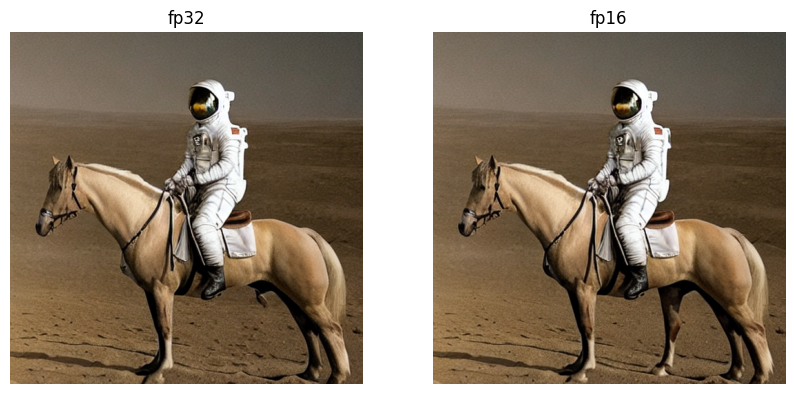

In [ ]:
# [실험 A2] fp32 vs fp16 (같은 시드 42, guidance 7.5, steps 30): 시간과 GPU 메모리
import gc
import time
import torch
import matplotlib.pyplot as plt
from diffusers import StableDiffusionPipeline
del pipe
gc.collect()
torch.cuda.empty_cache()
prompt = 'A photo of man riding a horse in the moon wearing astronaut outfits'
res = {}
for name, dt in [('fp32', torch.float32), ('fp16', torch.float16)]:
    p = StableDiffusionPipeline.from_pretrained('runwayml/stable-diffusion-v1-5', torch_dtype=dt).to('cuda')
    p(prompt, num_inference_steps=2)
    torch.cuda.reset_peak_memory_stats()
    gen = torch.Generator('cuda').manual_seed(42)
    torch.cuda.synchronize()
    t = time.time()
    img = p(prompt, num_inference_steps=30, guidance_scale=7.5, generator=gen).images[0]
    torch.cuda.synchronize()
    res[name] = img
    print(f'{name}: time={time.time() - t:.2f}s  peak_GPU_memory={torch.cuda.max_memory_allocated() / 1e9:.2f}GB')
    del p
    gc.collect()
    torch.cuda.empty_cache()
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
for a, k in zip(ax, ['fp32', 'fp16']):
    a.imshow(res[k])
    a.set_title(k)
    a.axis('off')
plt.show()

## 실험 B1. 실제 PCB 사진에 crack Inpainting
- 조건: 정상 PCB 512×512, 가운데 작은 직사각형 마스크, "a crack on the circuit board, broken trace", steps 50, guidance 7.5
- **내 예측**: 공장에서 나온 실제 정상 사진을 썼으니 회색판보다는 그럴듯하겠지만, 어딘가 뭉개지긴 할 것 같다.
- 첫 시도는 SD2 inpainting 401로 실패 (아래 셀 출력). 다음 셀에서 SD1.5 계열로 교체.

In [ ]:
# [실험 B1] 실제 PCB 사진에 Inpainting (마스크 안만 crack). 바깥 글자가 보존되는지 확대 비교
import shutil
import torch
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from google.colab import drive
from diffusers import StableDiffusionInpaintPipeline
drive.mount('/content/drive')
shutil.copy('/content/drive/MyDrive/normal.png의 사본', '/content/normal.png')
init = Image.open('/content/normal.png').convert('RGB').resize((512, 512))
mask = Image.new('L', (512, 512), 0)
ImageDraw.Draw(mask).rectangle([200, 250, 300, 300], fill=255)
pipe_in = StableDiffusionInpaintPipeline.from_pretrained('stabilityai/stable-diffusion-2-inpainting', torch_dtype=torch.float16).to('cuda')
gen = torch.Generator('cuda').manual_seed(42)
out = pipe_in(prompt='a crack on the circuit board, broken trace', negative_prompt='smooth, perfect, clean, blurry', image=init, mask_image=mask, num_inference_steps=50, guidance_scale=7.5, generator=gen).images[0]
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, im, t in zip(ax, [init, mask, out], ['original', 'mask', 'inpainted']):
    a.imshow(im, cmap='gray' if t == 'mask' else None)
    a.set_title(t)
    a.axis('off')
plt.show()
box = (130, 90, 330, 190)
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
for a, im, t in zip(ax, [init, out], ['original (zoom, outside mask)', 'inpainted (zoom, outside mask)']):
    a.imshow(im.crop(box).resize((600, 300)))
    a.set_title(t)
    a.axis('off')
plt.show()

Mounted at /content/drive


OSError: Cannot load model stabilityai/stable-diffusion-2-inpainting: the model is not fully cached locally (Cannot find an appropriate cached snapshot folder for the specified revision on the local disk and outgoing traffic has been disabled. To enable repo look-ups and downloads online, pass 'local_files_only=False' as input.) and an error occurred while trying to fetch metadata from the Hub. Please check out the root cause in the stacktrace above.

**B1 재시도 결과와 해석**
- **결과**: 배경은 진짜 PCB처럼 자연스럽지만 균열은 거의 없고, 마스크 **바깥** 글자(`IN+`, `R400`, `FC-75`)까지 뭉개졌다.
- 다시 볼 때(10-10) 생각: 마스크 바깥은 원본이 남아야 할 것 같지만, 모델이 사진을 한 번 압축했다가 복원하는 구조라 원본이 그대로 살아 있다는 보장은 없다.
- **해석**: 사진 전체가 64×64 latent로 압축됐다 복원된다. 균열이 안 생긴 건 SD가 인터넷 사진으로 학습해서 PCB 기판 균열을 거의 못 봤기 때문으로 보인다.

Mounted at /content/drive


model_index.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

loaded: runwayml/stable-diffusion-inpainting


  0%|          | 0/50 [00:00<?, ?it/s]

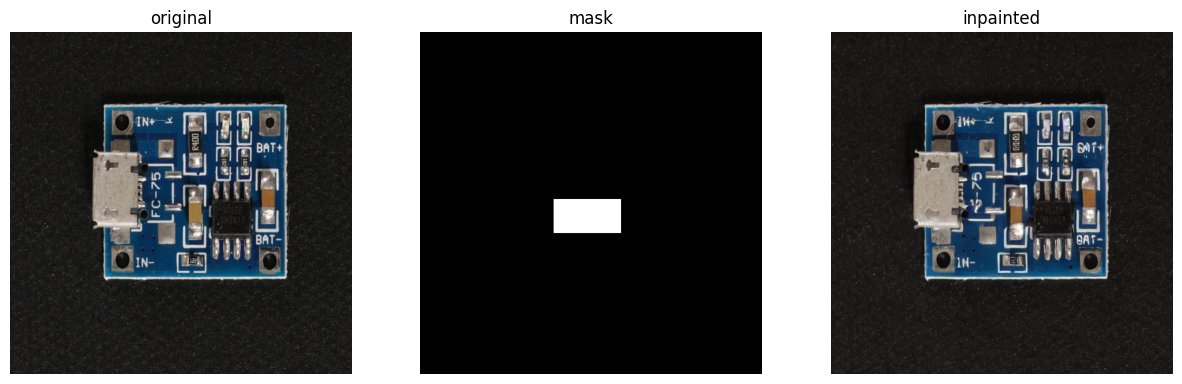

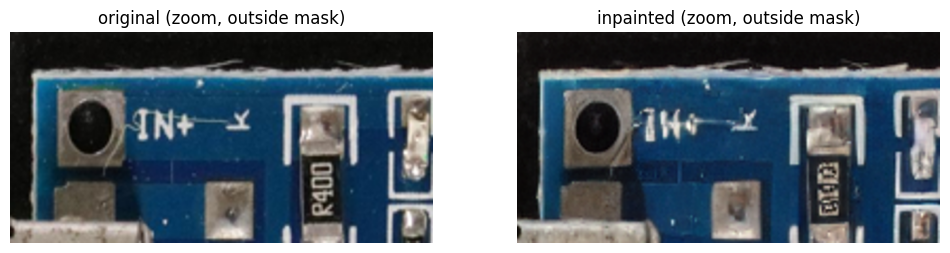

In [2]:
# [실험 B1 재시도] SD2 inpainting 모델이 Hub에서 사라져 401 → SD1.5 계열 inpainting 모델로 교체 (나머지 조건 동일)
import shutil
import torch
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from google.colab import drive
from diffusers import AutoPipelineForInpainting
drive.mount('/content/drive')
shutil.copy('/content/drive/MyDrive/normal.png의 사본', '/content/normal.png')
init = Image.open('/content/normal.png').convert('RGB').resize((512, 512))
mask = Image.new('L', (512, 512), 0)
ImageDraw.Draw(mask).rectangle([200, 250, 300, 300], fill=255)
pipe_in = None
for mid in ['runwayml/stable-diffusion-inpainting', 'stable-diffusion-v1-5/stable-diffusion-inpainting', 'Lykon/dreamshaper-8-inpainting']:
    try:
        pipe_in = AutoPipelineForInpainting.from_pretrained(mid, torch_dtype=torch.float16).to('cuda')
        print('loaded:', mid)
        break
    except Exception as e:
        print('failed:', mid, type(e).__name__)
gen = torch.Generator('cuda').manual_seed(42)
out = pipe_in(prompt='a crack on the circuit board, broken trace', negative_prompt='smooth, perfect, clean, blurry', image=init, mask_image=mask, num_inference_steps=50, guidance_scale=7.5, generator=gen).images[0]
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, im, t in zip(ax, [init, mask, out], ['original', 'mask', 'inpainted']):
    a.imshow(im, cmap='gray' if t == 'mask' else None)
    a.set_title(t)
    a.axis('off')
plt.show()
box = (130, 90, 330, 190)
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
for a, im, t in zip(ax, [init, out], ['original (zoom, outside mask)', 'inpainted (zoom, outside mask)']):
    a.imshow(im.crop(box).resize((600, 300)))
    a.set_title(t)
    a.axis('off')
plt.show()

## 실험 B2. 마스크 바깥에 원본 픽셀 되붙이기
- **내 예측**: 원본을 붙여 넣으면 바깥은 당연히 똑같아질 것이다. 대신 마스크 경계는 서로 다른 두 사진을 붙인 것처럼 보일 수 있다.
- **결과**: 둘 다 맞음. 글자는 돌아왔고 경계에 직선 이음새가 생겼다.
- **해석**: 이음새는 실제 불량에 없는 흔적이라, 불량 라벨을 붙이면 모델이 이음새를 불량 특징으로 배울 수 있다.

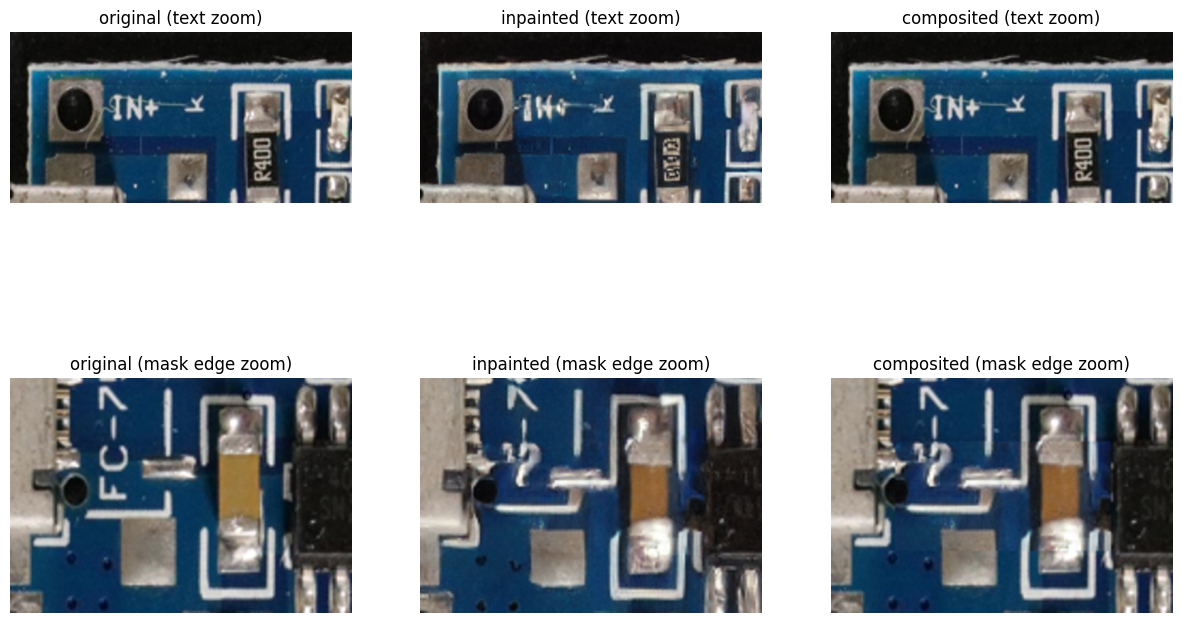

In [3]:
# [실험 B2] 생성 후 마스크 바깥은 원본 픽셀로 되돌리기 (글자 보존 + 경계 확인)
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
m3 = (np.array(mask.resize(out.size)) / 255.0)[..., None]
comp = Image.fromarray((np.array(out) * m3 + np.array(init.resize(out.size)) * (1 - m3)).astype('uint8'))
box = (130, 90, 330, 190)
edge = (170, 220, 330, 330)
fig, ax = plt.subplots(2, 3, figsize=(15, 9))
for a, im, t in zip(ax[0], [init, out, comp], ['original', 'inpainted', 'composited']):
    a.imshow(im.crop(box).resize((600, 300)))
    a.set_title(t + ' (text zoom)')
    a.axis('off')
for a, im, t in zip(ax[1], [init, out, comp], ['original', 'inpainted', 'composited']):
    a.imshow(im.crop(edge).resize((480, 330)))
    a.set_title(t + ' (mask edge zoom)')
    a.axis('off')
plt.show()

## 실험 A3. num_inference_steps 10 / 20 / 30 / 50 (10-14 추가)
- 생성 모델은 학습하지 않으니 epoch 대신 steps가 "몇 단계면 충분한가"를 정한다. 노트북의 30, 50에 근거가 없어서 확인.
- **결과**: 시간은 단계 수에 비례(1.73 → 7.59초). 20에서 형태가 잡히고 30에서 바이저 반사 같은 세부가 생김. 50은 더 좋아지지 않음.
- **내 판단** (결과를 본 뒤): 균열 결함을 만든다면 30으로 하겠다. 20→30에서 세부가 생겼다. 20이 30%쯤 빠르지만 균열은 가늘고 작은 결함이라 세부가 중요하다고 봄.

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

...

STEPS 20 time=3.11s


  0%|          | 0/30 [00:00<?, ?it/s]

STEPS 30 time=4.51s


  0%|          | 0/50 [00:00<?, ?it/s]

STEPS 50 time=7.59s


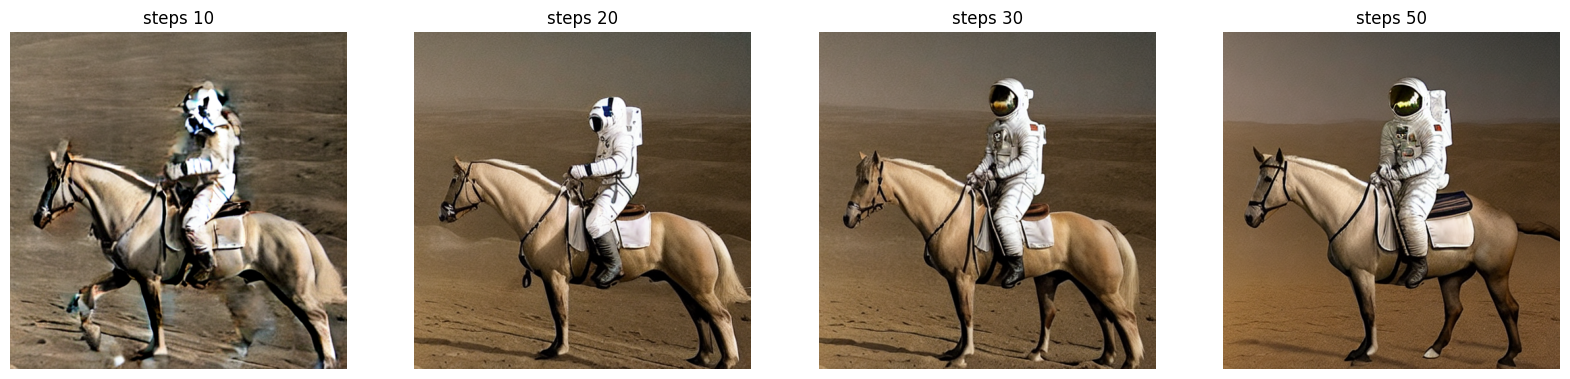

In [1]:
# [실험 A3] num_inference_steps 10 / 20 / 30 / 50: 몇 단계부터 그림이 더 안 좋아지나 (시드 42, guidance 7.5, fp16)
# 생성 모델은 학습하지 않으니 epoch 대신 steps가 "적절한 상태"를 정하는 값이다.
import time
import torch
import matplotlib.pyplot as plt
from diffusers import StableDiffusionPipeline
try:
    pipe = StableDiffusionPipeline.from_pretrained('runwayml/stable-diffusion-v1-5', torch_dtype=torch.float16).to('cuda')
except Exception as e:
    print('runwayml 실패 → 미러 사용:', type(e).__name__)
    pipe = StableDiffusionPipeline.from_pretrained('stable-diffusion-v1-5/stable-diffusion-v1-5', torch_dtype=torch.float16).to('cuda')
prompt = 'A photo of man riding a horse in the moon wearing astronaut outfits'
pipe(prompt, num_inference_steps=2)
steps_list = [10, 20, 30, 50]
imgs = []
for n in steps_list:
    gen = torch.Generator('cuda').manual_seed(42)
    torch.cuda.synchronize()
    t = time.time()
    img = pipe(prompt, num_inference_steps=n, guidance_scale=7.5, generator=gen).images[0]
    torch.cuda.synchronize()
    print(f'STEPS {n:2d} time={time.time() - t:.2f}s')
    imgs.append(img)
fig, ax = plt.subplots(1, 4, figsize=(20, 5))
for a, im, n in zip(ax, imgs, steps_list):
    a.imshow(im)
    a.set_title(f'steps {n}')
    a.axis('off')
plt.show()

# 회고 (KPT)

**Keep**

- 돌리기 전에 결과를 먼저 말로 예상해 본 것. guidance가 크면 느려질 거라고 했는데 셋 다 4.5초였고, 여기서 guidance가 뭔지 제대로 알게 됐다.
- OOM이 났을 때 "해상도" 가설을 그냥 믿지 않고 AnomalyAny 소스를 열어 생성 크기가 512로 고정된 것을 확인한 것.
- 사흘 뒤 노트북을 처음부터 다시 보면서 attention map과 결과를 나란히 놓고, 처음 판단("균열 안 생김")을 고친 것.

**Problem**

- 처음엔 "본 적 없는 결함을 그린다"를 "원본을 바꿔서 그린다"로 이해했다. 모델은 그대로이고 생성 과정을 바꾼다는 걸 몰랐다.
- 오탐과 미탐의 이름을 두 번 바꿔 말했다. "경보를 울렸는데 틀림 = 오탐, 못 울림 = 미탐"으로 정리했다.
- C1의 실패한 시도 셀을 같은 노트북에서 다시 실행해서, 512 재시도의 OOM 출력이 덮어써졌다.
- AnomalyAny 결과를 처음엔 4장 중 1장만 보고 "커넥터에 균열을 그렸다"고 정리했다. 나머지 3장을 보고 나서 고쳤다. 시드가 랜덤이라 재현도 안 된다.

**Try / Action**

- [ ] L4 또는 A100 런타임에서 C1(원본 충실도 0.3 vs 0.7)을 같은 시드로 돌려 글자 보존과 균열 강도를 비교한다.
- [ ] B2의 마스크 경계를 가우시안 블러로 흐리게 섞어(feathering) 이음새가 사라지는지 확대 사진으로 확인한다.
- [ ] AnomalyAny 결과에 B2 되붙이기를 적용해, 커넥터 균열만 남기고 글자를 원본으로 돌린 사진을 만든다.
- [ ] 생성 불량 사진이 지름길을 만드는지 확인한다: 정상 실사진 vs 생성 불량으로 분류기를 학습한 뒤, 정상 사진의 글자만 살짝 흐리게 했을 때 불량으로 판정하는지 본다.